# Demand Forecasting & Inventory Decision Analytics

## 1. Business problem

A manufacturing business needs to balance product availability with the cost of holding inventory. This project reviews weekly demand, tests simple forecasting methods, identifies inventory risk, and investigates replenishment lead times.

The data is synthetic and uses fictional products, locations, and suppliers. Findings demonstrate an analytics workflow; they are not claims about a real company's performance or savings.

**Questions**
- What does demand look like over time and across products?
- Which forecast method performs best on the selected product-location series?
- Where are stockout and excess-inventory flags concentrated?
- What should be reviewed for the highest-risk product-location combination?

## 2. Load the data

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

data_folder = "/content"

demand = pd.read_csv(os.path.join(data_folder, "Demand.csv"))
inventory = pd.read_csv(os.path.join(data_folder, "Inventory_Snapshot.csv"))
products = pd.read_csv(os.path.join(data_folder, "Products.csv"))
locations = pd.read_csv(os.path.join(data_folder, "Locations.csv"))
purchase_orders = pd.read_csv(os.path.join(data_folder, "Purchase_Orders.csv"))
suppliers = pd.read_csv(os.path.join(data_folder, "Suppliers.csv"))
calendar = pd.read_csv(os.path.join(data_folder, "Calendar.csv"))

print("Demand:", demand.shape)
print("Inventory:", inventory.shape)
print("Products:", products.shape)
print("Locations:", locations.shape)
print("Purchase orders:", purchase_orders.shape)
print("Suppliers:", suppliers.shape)
print("Calendar:", calendar.shape)

Demand: (27500, 6)
Inventory: (27475, 11)
Products: (35, 9)
Locations: (7, 4)
Purchase orders: (7369, 12)
Suppliers: (10, 5)
Calendar: (157, 8)


## 3. Check demand data

In [5]:
demand["Date"] = pd.to_datetime(demand["Date"])

print("Rows:", len(demand))
print("Exact duplicate rows:", demand.duplicated().sum())
print("Missing demand values:", demand["Demand_Units"].isna().sum())
print("Negative demand values:", (demand["Demand_Units"] < 0).sum())

Rows: 27500
Exact duplicate rows: 25
Missing demand values: 27
Negative demand values: 0


In [6]:
# Look at duplicate records before removing them.
duplicate_rows = demand[demand.duplicated(keep=False)]
duplicate_rows.head(10)

,Date,Product_ID,Location_ID,Demand_Units,Demand_Event_Flag,Demand_Type
889,2024-12-30,PRD-1002,LOC-03,78.0,0,Regular
1800,2024-05-27,PRD-1003,LOC-06,105.0,0,Regular
5069,2023-11-13,PRD-1007,LOC-07,111.0,0,Regular
5741,2024-09-16,PRD-1008,LOC-03,69.0,0,Regular
7585,2023-12-11,PRD-1010,LOC-02,98.0,0,Regular
8207,2023-10-30,PRD-1011,LOC-01,142.0,0,Regular
8842,2023-12-18,PRD-1012,LOC-01,69.0,0,Regular
10315,2025-02-10,PRD-1013,LOC-03,30.0,0,Regular
11605,2025-10-06,PRD-1015,LOC-01,54.0,0,Regular
13947,2025-07-07,PRD-1018,LOC-07,36.0,0,Regular


In [7]:
demand_clean = demand.drop_duplicates().copy()

print("Rows before cleaning:", len(demand))
print("Rows after removing exact duplicates:", len(demand_clean))
print("Duplicates remaining:", demand_clean.duplicated().sum())

Rows before cleaning: 27500
Rows after removing exact duplicates: 27475
Duplicates remaining: 0


In [8]:
# Check whether the expected product-location-week grain is unique.
grain_duplicates = demand_clean.duplicated(
    subset=["Date", "Product_ID", "Location_ID"]
).sum()

print("Duplicate product-location-week keys:", grain_duplicates)
print("Date range:", demand_clean["Date"].min(), "to", demand_clean["Date"].max())
print("Unique weeks:", demand_clean["Date"].nunique())

Duplicate product-location-week keys: 0
Date range: 2023-01-02 00:00:00 to 2025-12-29 00:00:00
Unique weeks: 157


In [9]:
# Review records where demand is unknown.
missing_demand_rows = demand_clean[demand_clean["Demand_Units"].isna()]
missing_demand_rows.head(10)

,Date,Product_ID,Location_ID,Demand_Units,Demand_Event_Flag,Demand_Type
2128,2024-09-02,PRD-1004,LOC-04,NaN,0,Regular
3162,2023-06-05,PRD-1005,LOC-01,NaN,0,Regular
3332,2023-09-04,PRD-1005,LOC-05,NaN,0,Regular
3348,2023-12-25,PRD-1005,LOC-05,NaN,0,Regular
3497,2023-10-30,PRD-1005,LOC-02,NaN,0,Regular
3938,2023-04-03,PRD-1006,LOC-03,NaN,0,Regular
4070,2025-10-13,PRD-1006,LOC-03,NaN,1,Project_Order
6791,2023-10-09,PRD-1009,LOC-06,NaN,0,Regular
6810,2024-02-19,PRD-1009,LOC-06,NaN,0,Regular
7178,2025-03-03,PRD-1010,LOC-06,NaN,0,Regular


**Data-quality decision:** exact duplicate rows are removed. Missing demand is retained as missing for inspection. The selected forecasting series will exclude missing target values, but the missing values are not re-labelled as zero.

## 4. Explore demand

In [10]:
product_demand = (
    demand_clean.groupby("Product_ID")["Demand_Units"]
    .sum()
    .sort_values(ascending=False)
)

product_demand.head(10)

,Demand_Units
Product_ID,
PRD-1006,129252.0
PRD-1003,112802.0
PRD-1016,106552.0
PRD-1011,105197.0
PRD-1004,103891.0
PRD-1007,96219.0
PRD-1027,91014.0
PRD-1005,85422.0
PRD-1023,83088.0


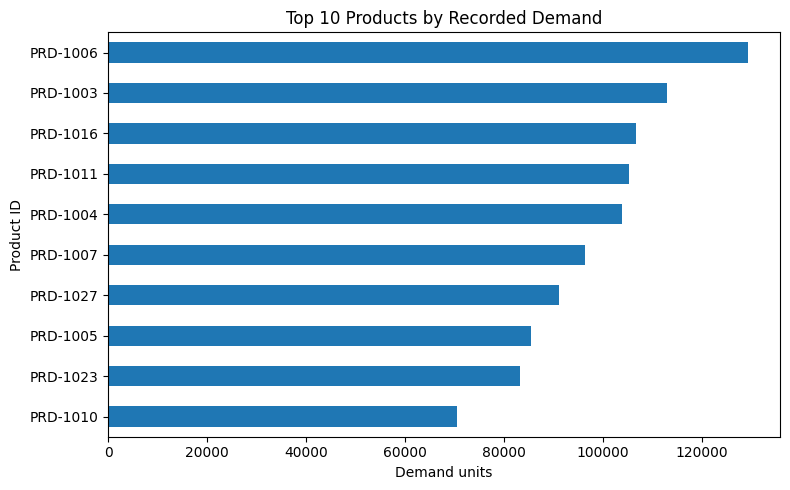

In [11]:
product_demand.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Products by Recorded Demand")
plt.xlabel("Demand units")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()

In [12]:
product_variability = (
    demand_clean.groupby("Product_ID")["Demand_Units"]
    .std()
    .sort_values(ascending=False)
)

product_variability.head(10)

,Demand_Units
Product_ID,
PRD-1016,49.283475
PRD-1033,42.919149
PRD-1022,36.722172
PRD-1005,34.373578
PRD-1003,33.493295
PRD-1035,33.341455
PRD-1019,32.898966
PRD-1027,32.143417
PRD-1011,31.194186


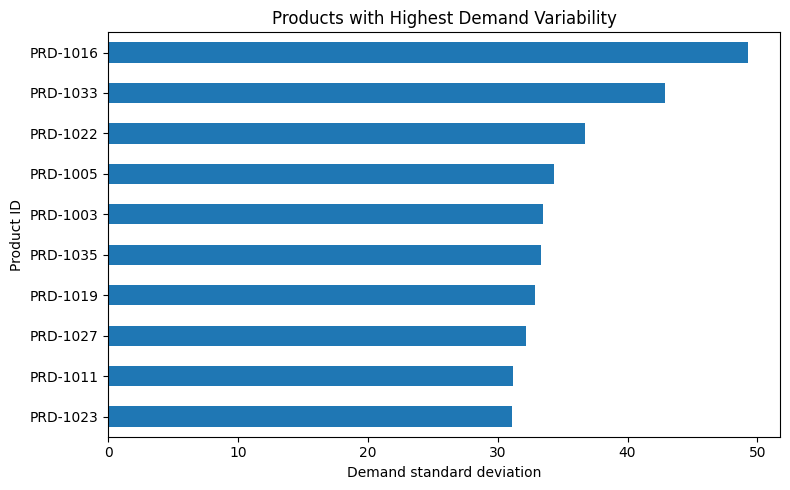

In [13]:
product_variability.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Products with Highest Demand Variability")
plt.xlabel("Demand standard deviation")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()

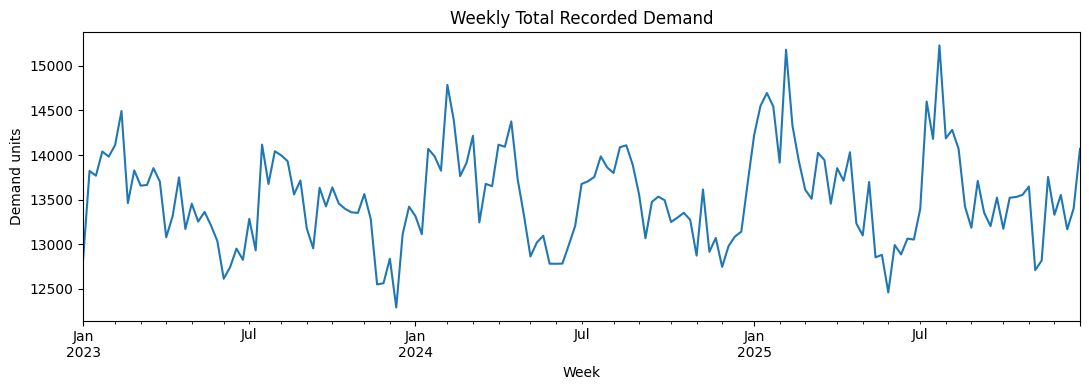

In [14]:
weekly_demand = (
    demand_clean.groupby("Date")["Demand_Units"]
    .sum()
    .sort_index()
)

weekly_demand.plot(figsize=(11, 4))
plt.title("Weekly Total Recorded Demand")
plt.xlabel("Week")
plt.ylabel("Demand units")
plt.tight_layout()
plt.show()

## 5. Forecast a selected series

In [15]:
product_id = "PRD-1001"
location_id = "LOC-03"

product_location_demand = demand_clean[
    (demand_clean["Product_ID"] == product_id) &
    (demand_clean["Location_ID"] == location_id)
].copy()

product_location_demand = product_location_demand[
    ["Date", "Demand_Units"]
].sort_values("Date").reset_index(drop=True)

# Unknown target values are excluded from this model series.
product_location_demand = product_location_demand.dropna(
    subset=["Demand_Units"]
).copy()

print("Observations:", len(product_location_demand))
print("First date:", product_location_demand["Date"].min())
print("Last date:", product_location_demand["Date"].max())
product_location_demand.head()

Observations: 157
First date: 2023-01-02 00:00:00
Last date: 2025-12-29 00:00:00


,Date,Demand_Units
0,2023-01-02,26.0
1,2023-01-09,27.0
2,2023-01-16,38.0
3,2023-01-23,33.0
4,2023-01-30,36.0


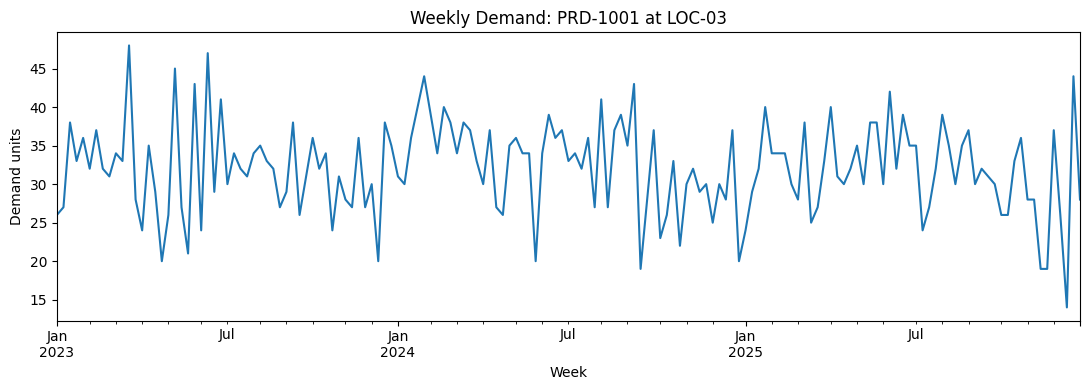

In [16]:
product_location_demand.plot(
    x="Date", y="Demand_Units", figsize=(11, 4), legend=False
)
plt.title("Weekly Demand: PRD-1001 at LOC-03")
plt.xlabel("Week")
plt.ylabel("Demand units")
plt.tight_layout()
plt.show()

In [17]:
product_location_demand["Demand_Units"].describe()

,Demand_Units
count,157.000000
mean,32.031847
std,6.010056
min,14.000000
25%,28.000000
50%,32.000000
75%,36.000000
max,48.000000


## 6. Split the time series

We use the first 80% of observations for training and the final 20% for testing. The rows stay in date order; time-series observations should not be randomly shuffled.

The model and all baseline forecasts will be evaluated on the same test dates.

In [18]:
split_index = int(len(product_location_demand) * 0.8)

train = product_location_demand.iloc[:split_index].copy()
test = product_location_demand.iloc[split_index:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training ends:", train["Date"].max())
print("Test starts:", test["Date"].min())

Training observations: 125
Testing observations: 32
Training ends: 2025-05-19 00:00:00
Test starts: 2025-05-26 00:00:00


In [19]:
# Naive forecast: repeat the last demand value from training.
last_train_demand = train["Demand_Units"].iloc[-1]
naive_forecast = np.repeat(last_train_demand, len(test))

print("Last training demand:", last_train_demand)

Last training demand: 38.0


In [20]:
# Four-week moving average: use the last four training observations.
moving_average_value = train["Demand_Units"].tail(4).mean()
moving_average_forecast = np.repeat(moving_average_value, len(test))

print("Last four training demands:", train["Demand_Units"].tail(4).tolist())
print("Moving-average forecast:", round(moving_average_value, 2))

Last four training demands: [32.0, 35.0, 30.0, 38.0]
Moving-average forecast: 33.75


In [21]:
actual = test["Demand_Units"].to_numpy()

naive_mae = mean_absolute_error(actual, naive_forecast)
naive_rmse = np.sqrt(mean_squared_error(actual, naive_forecast))
moving_mae = mean_absolute_error(actual, moving_average_forecast)
moving_rmse = np.sqrt(mean_squared_error(actual, moving_average_forecast))

print("Naive MAE:", round(naive_mae, 2))
print("Naive RMSE:", round(naive_rmse, 2))
print("Moving-average MAE:", round(moving_mae, 2))
print("Moving-average RMSE:", round(moving_rmse, 2))

Naive MAE: 7.59
Naive RMSE: 9.49
Moving-average MAE: 5.53
Moving-average RMSE: 7.07


In [22]:
baseline_results = pd.DataFrame({
    "Date": test["Date"].to_numpy(),
    "Actual_Demand": actual,
    "Naive_Forecast": naive_forecast,
    "Moving_Average_Forecast": moving_average_forecast
})

baseline_results.head()

,Date,Actual_Demand,Naive_Forecast,Moving_Average_Forecast
0,2025-05-26,38.0,38.0,33.75
1,2025-06-02,30.0,38.0,33.75
2,2025-06-09,42.0,38.0,33.75
3,2025-06-16,32.0,38.0,33.75
4,2025-06-23,39.0,38.0,33.75


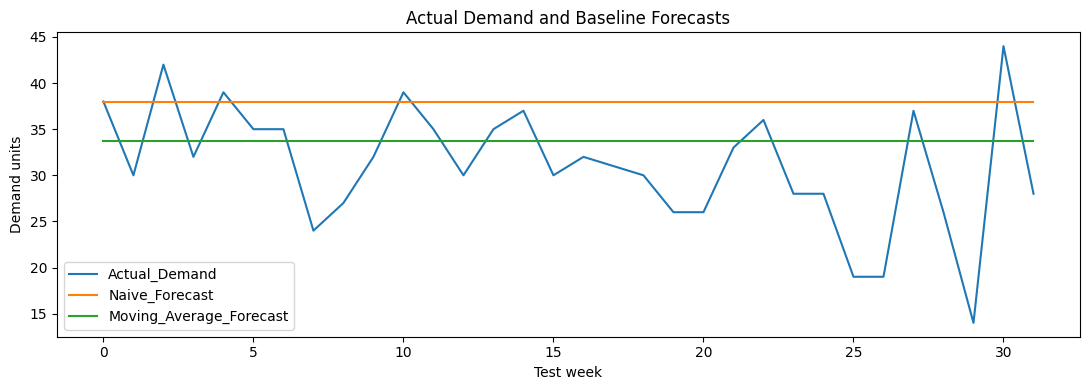

In [23]:
baseline_results[["Actual_Demand", "Naive_Forecast", "Moving_Average_Forecast"]].plot(
    figsize=(11, 4)
)
plt.title("Actual Demand and Baseline Forecasts")
plt.xlabel("Test week")
plt.ylabel("Demand units")
plt.tight_layout()
plt.show()

## 7. Train Linear Regression

In [24]:
forecast_data = product_location_demand.copy()

forecast_data["Demand_Lag_1"] = forecast_data["Demand_Units"].shift(1)
forecast_data["Demand_Rolling_Mean_4"] = (
    forecast_data["Demand_Units"].shift(1).rolling(4).mean()
)
forecast_data["Month"] = forecast_data["Date"].dt.month
forecast_data["Week_Of_Year"] = (
    forecast_data["Date"].dt.isocalendar().week.astype(int)
)

print("Missing values created by feature engineering:")
print(forecast_data[[
    "Demand_Lag_1", "Demand_Rolling_Mean_4"
]].isna().sum())

Missing values created by feature engineering:
Demand_Lag_1             1
Demand_Rolling_Mean_4    4
dtype: int64


In [25]:
model_data = forecast_data.dropna().copy()

split_index_ml = int(len(model_data) * 0.8)
train_ml = model_data.iloc[:split_index_ml].copy()
test_ml = model_data.iloc[split_index_ml:].copy()

feature_columns = [
    "Demand_Lag_1",
    "Demand_Rolling_Mean_4",
    "Month",
    "Week_Of_Year"
]

X_train = train_ml[feature_columns]
y_train = train_ml["Demand_Units"]
X_test = test_ml[feature_columns]
y_test = test_ml["Demand_Units"]

print("Training rows for model:", len(X_train))
print("Test rows for model:", len(X_test))
print("Training ends:", train_ml["Date"].max())
print("Test starts:", test_ml["Date"].min())

Training rows for model: 122
Test rows for model: 31
Training ends: 2025-05-26 00:00:00
Test starts: 2025-06-02 00:00:00


The first four rows are lost when the rolling-average feature is created. We split the feature-ready rows chronologically, so all models use exactly the same test dates in the final comparison.

In [26]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression training complete.")

Linear Regression training complete.


## 8. Recursive forecast

In [27]:
history = train_ml["Demand_Units"].tolist()
recursive_forecast = []

for _, row in test_ml.iterrows():
    lag_1 = history[-1]
    rolling_mean_4 = sum(history[-4:]) / 4

    next_week = pd.DataFrame([{
        "Demand_Lag_1": lag_1,
        "Demand_Rolling_Mean_4": rolling_mean_4,
        "Month": row["Month"],
        "Week_Of_Year": row["Week_Of_Year"]
    }])

    prediction = model.predict(next_week)[0]
    recursive_forecast.append(prediction)
    history.append(prediction)

print("Recursive forecasts created:", len(recursive_forecast))
print("First five forecasts:", [round(x, 2) for x in recursive_forecast[:5]])

Recursive forecasts created: 31
First five forecasts: [np.float64(31.88), np.float64(32.74), np.float64(32.93), np.float64(32.87), np.float64(32.83)]


In [28]:
actual_model = test_ml["Demand_Units"].to_numpy()

recursive_mae = mean_absolute_error(actual_model, recursive_forecast)
recursive_rmse = np.sqrt(mean_squared_error(actual_model, recursive_forecast))
recursive_bias = np.mean(actual_model - np.array(recursive_forecast))

print("Recursive forecast MAE:", round(recursive_mae, 2))
print("Recursive forecast RMSE:", round(recursive_rmse, 2))
print("Bias (actual - forecast):", round(recursive_bias, 2))

Recursive forecast MAE: 5.03
Recursive forecast RMSE: 6.44
Bias (actual - forecast): -0.18


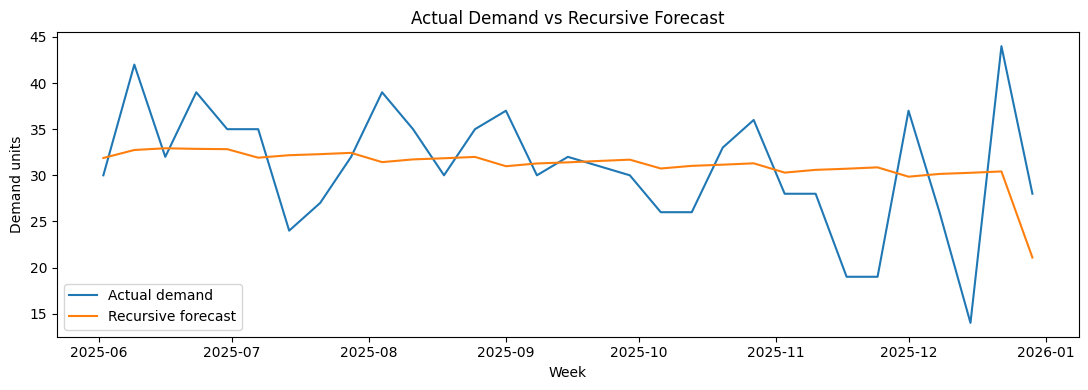

In [29]:
plt.figure(figsize=(11, 4))
plt.plot(test_ml["Date"], actual_model, label="Actual demand")
plt.plot(test_ml["Date"], recursive_forecast, label="Recursive forecast")
plt.title("Actual Demand vs Recursive Forecast")
plt.xlabel("Week")
plt.ylabel("Demand units")
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
forecast_errors = test_ml[["Date", "Demand_Units"]].copy()
forecast_errors["Predicted_Demand"] = recursive_forecast
forecast_errors["Error"] = (
    forecast_errors["Demand_Units"] - forecast_errors["Predicted_Demand"]
)
forecast_errors["Absolute_Error"] = forecast_errors["Error"].abs()

print("Largest underforecasts:")
display(forecast_errors.sort_values("Error", ascending=False).head(5))

print("Largest overforecasts:")
display(forecast_errors.sort_values("Error").head(5))

Largest underforecasts:


,Date,Demand_Units,Predicted_Demand,Error,Absolute_Error
155,2025-12-22,44.0,30.419367,13.580633,13.580633
127,2025-06-09,42.0,32.744747,9.255253,9.255253
135,2025-08-04,39.0,31.428351,7.571649,7.571649
152,2025-12-01,37.0,29.851439,7.148561,7.148561
156,2025-12-29,28.0,21.083663,6.916337,6.916337


Largest overforecasts:


,Date,Demand_Units,Predicted_Demand,Error,Absolute_Error
154,2025-12-15,14.0,30.272812,-16.272812,16.272812
151,2025-11-24,19.0,30.860322,-11.860322,11.860322
150,2025-11-17,19.0,30.713692,-11.713692,11.713692
132,2025-07-14,24.0,32.179447,-8.179447,8.179447
133,2025-07-21,27.0,32.292806,-5.292806,5.292806


## 9. Compare all forecasting methods

In [31]:
naive_for_model = np.repeat(train_ml["Demand_Units"].iloc[-1], len(test_ml))
moving_average_for_model = np.repeat(
    train_ml["Demand_Units"].tail(4).mean(), len(test_ml)
)

model_results = []

for name, predictions in [
    ("Naive", naive_for_model),
    ("4-Week Moving Average", moving_average_for_model),
    ("Linear Regression - Recursive", recursive_forecast)
]:
    model_results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual_model, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual_model, predictions)),
        "Bias": np.mean(actual_model - predictions)
    })

model_comparison = pd.DataFrame(model_results).sort_values("MAE").reset_index(drop=True)
model_comparison.round(2)

,Model,MAE,RMSE,Bias
0,Linear Regression - Recursive,5.03,6.44,-0.18
1,4-Week Moving Average,6.07,7.85,-4.31
2,Naive,7.84,9.64,-7.06


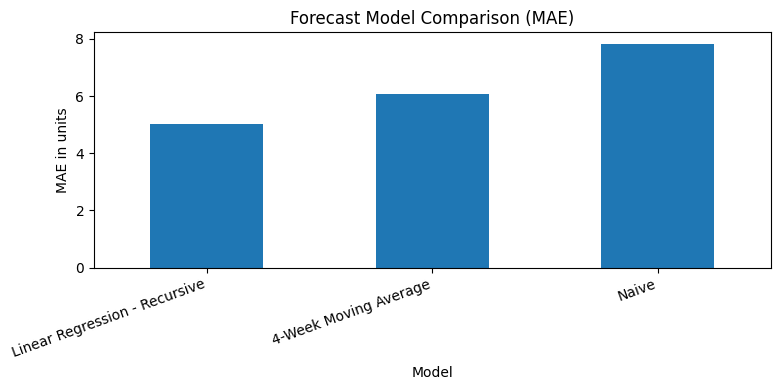

In [32]:
model_comparison.plot(x="Model", y="MAE", kind="bar", legend=False, figsize=(8, 4))
plt.title("Forecast Model Comparison (MAE)")
plt.xlabel("Model")
plt.ylabel("MAE in units")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [33]:
naive_mae_fair = model_comparison.loc[
    model_comparison["Model"] == "Naive", "MAE"
].iloc[0]
moving_mae_fair = model_comparison.loc[
    model_comparison["Model"] == "4-Week Moving Average", "MAE"
].iloc[0]

naive_improvement = (naive_mae_fair - recursive_mae) / naive_mae_fair * 100
moving_improvement = (moving_mae_fair - recursive_mae) / moving_mae_fair * 100

print("MAE reduction vs naive (%):", round(naive_improvement, 2))
print("MAE reduction vs moving average (%):", round(moving_improvement, 2))

MAE reduction vs naive (%): 35.79
MAE reduction vs moving average (%): 17.11


**Interpretation:** use the calculated table, rather than assuming a model wins. These results cover one product-location series and one test period only.

## 10. Inventory data checks

In [34]:
inventory["Date"] = pd.to_datetime(inventory["Date"])

print("Inventory shape:", inventory.shape)
print("Missing values by column:")
print(inventory.isna().sum())
print("Date range:", inventory["Date"].min(), "to", inventory["Date"].max())

Inventory shape: (27475, 11)
Missing values by column:
Date                       0
Product_ID                 0
Location_ID                0
Opening_Inventory_Units    0
Receipt_Units              0
Demand_Units               0
Closing_Inventory_Units    0
Inventory_Value            0
Safety_Stock_Units         0
Stockout_Flag              0
Excess_Inventory_Flag      0
dtype: int64
Date range: 2023-01-02 00:00:00 to 2025-12-29 00:00:00


In [35]:
inventory_duplicates = inventory.duplicated(
    subset=["Date", "Product_ID", "Location_ID"]
).sum()

print("Duplicate product-location-week keys:", inventory_duplicates)
print("Negative closing inventory rows:", (inventory["Closing_Inventory_Units"] < 0).sum())

Duplicate product-location-week keys: 0
Negative closing inventory rows: 0


In [36]:
inventory["Expected_Closing_Inventory"] = (
    inventory["Opening_Inventory_Units"]
    + inventory["Receipt_Units"]
    - inventory["Demand_Units"]
)

inventory["Inventory_Balance_Difference"] = (
    inventory["Closing_Inventory_Units"]
    - inventory["Expected_Closing_Inventory"]
)

inventory["Has_Balance_Discrepancy"] = (
    inventory["Inventory_Balance_Difference"].abs() > 0.01
)

print("Rows with balance discrepancy:", int(inventory["Has_Balance_Discrepancy"].sum()))
print(
    "Discrepancy rate (%):",
    round(inventory["Has_Balance_Discrepancy"].mean() * 100, 2)
)

Rows with balance discrepancy: 3140
Discrepancy rate (%): 11.43


In [37]:
print("Discrepancies by stockout flag:")
print(
    inventory.groupby("Stockout_Flag")["Has_Balance_Discrepancy"]
    .agg(["sum", "mean"])
)

Discrepancies by stockout flag:
                sum  mean
Stockout_Flag            
0                 0   0.0
1              3140   1.0


The balance difference is retained as a diagnostic. When demand exceeds available inventory, the simplified balance equation can imply a negative balance while the dataset records closing stock as zero. The fields do not establish whether unmet demand became a lost sale, backorder, or delayed shipment.

## 11. Inventory risk summary

In [38]:
total_snapshots = len(inventory)
stockout_count = inventory["Stockout_Flag"].sum()
excess_count = inventory["Excess_Inventory_Flag"].sum()

print("Total inventory snapshots:", total_snapshots)
print("Stockout snapshots:", int(stockout_count))
print("Stockout rate (%):", round(stockout_count / total_snapshots * 100, 2))
print("Excess snapshots:", int(excess_count))
print("Excess-inventory rate (%):", round(excess_count / total_snapshots * 100, 2))

Total inventory snapshots: 27475
Stockout snapshots: 3140
Stockout rate (%): 11.43
Excess snapshots: 151
Excess-inventory rate (%): 0.55


In [39]:
stockout_by_product = (
    inventory.groupby("Product_ID")
    .agg(
        Total_Snapshots=("Stockout_Flag", "size"),
        Stockout_Weeks=("Stockout_Flag", "sum")
    )
    .reset_index()
)

stockout_by_product["Stockout_Rate_Pct"] = (
    stockout_by_product["Stockout_Weeks"] /
    stockout_by_product["Total_Snapshots"] * 100
)

stockout_by_product = stockout_by_product.merge(
    products[["Product_ID", "Product_Name"]],
    on="Product_ID",
    how="left"
)

stockout_by_product.sort_values("Stockout_Rate_Pct", ascending=False).head(10)

,Product_ID,Total_Snapshots,Stockout_Weeks,Stockout_Rate_Pct,Product_Name
26,PRD-1027,785,237,30.191083,Conveyor Roller Assembly
4,PRD-1005,942,238,25.265393,Heavy-Duty Coupling
9,PRD-1010,785,179,22.802548,Industrial Bearing Carrier
22,PRD-1023,785,171,21.783439,Heavy Equipment Bush
34,PRD-1035,785,165,21.019108,Variable Speed Coupling
16,PRD-1017,785,143,18.216561,High-Pressure Piston Rod
13,PRD-1014,628,111,17.675159,Timing Pulley Hub
25,PRD-1026,628,110,17.515924,Pneumatic Manifold Plate
6,PRD-1007,942,165,17.515924,Stainless Process Flange
18,PRD-1019,628,102,16.242038,Actuator Linkage Kit


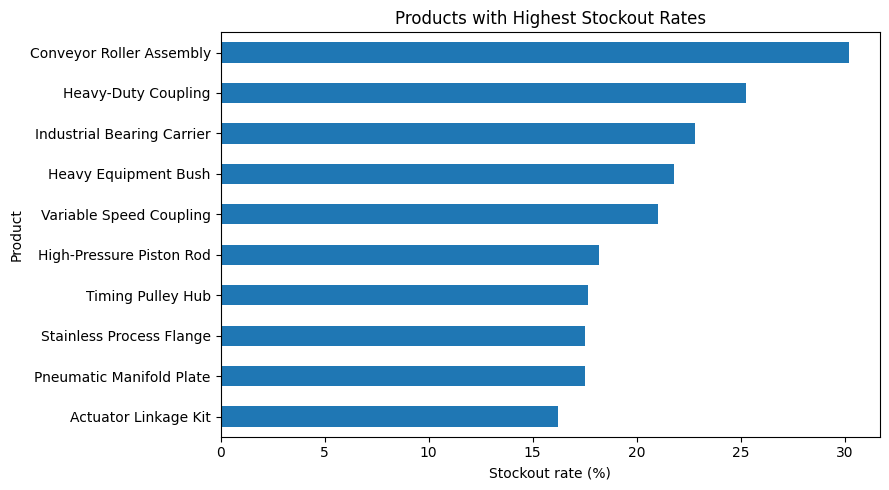

In [40]:
top_products = stockout_by_product.sort_values("Stockout_Rate_Pct").tail(10)
top_products.plot(x="Product_Name", y="Stockout_Rate_Pct", kind="barh", legend=False, figsize=(9, 5))
plt.title("Products with Highest Stockout Rates")
plt.xlabel("Stockout rate (%)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [41]:
stockout_by_location = (
    inventory.groupby("Location_ID")
    .agg(
        Total_Snapshots=("Stockout_Flag", "size"),
        Stockout_Weeks=("Stockout_Flag", "sum")
    )
    .reset_index()
)

stockout_by_location["Stockout_Rate_Pct"] = (
    stockout_by_location["Stockout_Weeks"] /
    stockout_by_location["Total_Snapshots"] * 100
)

stockout_by_location = stockout_by_location.merge(
    locations[["Location_ID", "Location_Name"]],
    on="Location_ID",
    how="left"
)

stockout_by_location.sort_values("Stockout_Rate_Pct", ascending=False)

,Location_ID,Total_Snapshots,Stockout_Weeks,Stockout_Rate_Pct,Location_Name
1,LOC-02,3925,582,14.828025,Pune Components Plant
4,LOC-05,3925,444,11.312102,Bengaluru Distribution Centre
5,LOC-06,3925,440,11.210191,Chennai Distribution Centre
2,LOC-03,4867,530,10.889665,Nashik Assembly Plant
0,LOC-01,3925,416,10.598726,Ahmedabad Manufacturing Plant
3,LOC-04,3454,364,10.538506,Mumbai Regional Warehouse
6,LOC-07,3454,364,10.538506,Delhi Industrial Warehouse


In [42]:
stockout_by_combination = (
    inventory.groupby(["Product_ID", "Location_ID"])
    .agg(
        Total_Weeks=("Stockout_Flag", "size"),
        Stockout_Weeks=("Stockout_Flag", "sum")
    )
    .reset_index()
)

stockout_by_combination["Stockout_Rate_Pct"] = (
    stockout_by_combination["Stockout_Weeks"] /
    stockout_by_combination["Total_Weeks"] * 100
)

stockout_by_combination = stockout_by_combination.merge(
    products[["Product_ID", "Product_Name", "Criticality",
              "Unit_Cost", "Standard_Lead_Time_Days"]],
    on="Product_ID",
    how="left"
)

stockout_by_combination = stockout_by_combination.merge(
    locations[["Location_ID", "Location_Name"]],
    on="Location_ID",
    how="left"
)

stockout_by_combination = stockout_by_combination.sort_values(
    "Stockout_Rate_Pct", ascending=False
)

stockout_by_combination[
    ["Product_ID", "Product_Name", "Location_ID", "Location_Name",
     "Criticality", "Standard_Lead_Time_Days", "Total_Weeks",
     "Stockout_Weeks", "Stockout_Rate_Pct"]
].head(10)

,Product_ID,Product_Name,Location_ID,Location_Name,Criticality,Standard_Lead_Time_Days,Total_Weeks,Stockout_Weeks,Stockout_Rate_Pct
134,PRD-1027,Conveyor Roller Assembly,LOC-02,Pune Components Plant,Medium,17,157,61,38.853503
130,PRD-1026,Pneumatic Manifold Plate,LOC-03,Nashik Assembly Plant,Medium,14,157,58,36.942675
30,PRD-1007,Stainless Process Flange,LOC-02,Pune Components Plant,Medium,10,157,58,36.942675
133,PRD-1027,Conveyor Roller Assembly,LOC-01,Ahmedabad Manufacturing Plant,Medium,17,157,58,36.942675
32,PRD-1007,Stainless Process Flange,LOC-04,Mumbai Regional Warehouse,Medium,10,157,53,33.757962
49,PRD-1010,Industrial Bearing Carrier,LOC-07,Delhi Industrial Warehouse,Medium,17,157,50,31.847134
23,PRD-1005,Heavy-Duty Coupling,LOC-07,Delhi Industrial Warehouse,Medium,16,157,50,31.847134
95,PRD-1019,Actuator Linkage Kit,LOC-06,Chennai Distribution Centre,Medium,12,157,50,31.847134
137,PRD-1027,Conveyor Roller Assembly,LOC-06,Chennai Distribution Centre,Medium,17,157,50,31.847134
114,PRD-1023,Heavy Equipment Bush,LOC-01,Ahmedabad Manufacturing Plant,Medium,15,157,48,30.573248


## 12. Investigate the priority combination

In [43]:
priority_product = "PRD-1027"
priority_location = "LOC-02"

priority_inventory = inventory[
    (inventory["Product_ID"] == priority_product) &
    (inventory["Location_ID"] == priority_location)
].copy()

priority_inventory = priority_inventory.sort_values("Date")

print("Weeks observed:", len(priority_inventory))
print("Stockout weeks:", int(priority_inventory["Stockout_Flag"].sum()))
print(
    "Stockout rate (%):",
    round(priority_inventory["Stockout_Flag"].mean() * 100, 2)
)

Weeks observed: 157
Stockout weeks: 61
Stockout rate (%): 38.85


In [44]:
priority_inventory[[
    "Date", "Opening_Inventory_Units", "Receipt_Units",
    "Demand_Units", "Closing_Inventory_Units",
    "Safety_Stock_Units", "Stockout_Flag"
]].head(10)

,Date,Opening_Inventory_Units,Receipt_Units,Demand_Units,Closing_Inventory_Units,Safety_Stock_Units,Stockout_Flag
21509,2023-01-02,454.4,0.0,95.0,359.4,90.9,0
21510,2023-01-09,359.4,0.0,74.0,285.4,90.9,0
21511,2023-01-16,285.4,0.0,57.0,228.4,90.9,0
21512,2023-01-23,228.4,0.0,137.0,91.4,90.9,0
21513,2023-01-30,91.4,0.0,152.0,0.0,90.9,1
21514,2023-02-06,0.0,0.0,131.0,0.0,90.9,1
21515,2023-02-13,0.0,310.0,71.0,239.0,90.9,0
21516,2023-02-20,239.0,0.0,117.0,122.0,90.9,0
21517,2023-02-27,122.0,0.0,147.0,0.0,90.9,1
21518,2023-03-06,0.0,0.0,128.0,0.0,90.9,1


In [45]:
demand_mean = priority_inventory["Demand_Units"].mean()
demand_std = priority_inventory["Demand_Units"].std()

print("Average weekly demand:", round(demand_mean, 2))
print("Demand standard deviation:", round(demand_std, 2))
print("Minimum weekly demand:", priority_inventory["Demand_Units"].min())
print("Maximum weekly demand:", priority_inventory["Demand_Units"].max())
print("Coefficient of variation:", round(demand_std / demand_mean, 2))
print("Average safety stock:", round(priority_inventory["Safety_Stock_Units"].mean(), 2))
print("Average closing inventory:", round(priority_inventory["Closing_Inventory_Units"].mean(), 2))
print(
    "Weeks with zero closing inventory:",
    int((priority_inventory["Closing_Inventory_Units"] == 0).sum())
)

Average weekly demand: 113.61
Demand standard deviation: 26.49
Minimum weekly demand: 0.0
Maximum weekly demand: 168.0
Coefficient of variation: 0.23
Average safety stock: 90.9
Average closing inventory: 98.19
Weeks with zero closing inventory: 61


In [46]:
stockout_weeks = priority_inventory[priority_inventory["Stockout_Flag"] == 1]
non_stockout_weeks = priority_inventory[priority_inventory["Stockout_Flag"] == 0]

print("Average demand in stockout weeks:", round(stockout_weeks["Demand_Units"].mean(), 2))
print("Average demand in non-stockout weeks:", round(non_stockout_weeks["Demand_Units"].mean(), 2))
print("Demand recorded in stockout weeks:", round(stockout_weeks["Demand_Units"].sum(), 2))
print("Stockout weeks:", len(stockout_weeks))
print("Non-stockout weeks:", len(non_stockout_weeks))

Average demand in stockout weeks: 115.93
Average demand in non-stockout weeks: 112.12
Demand recorded in stockout weeks: 7072.0
Stockout weeks: 61
Non-stockout weeks: 96


Demand recorded during stockout weeks is not confirmed lost sales. Some demand may have been backordered or fulfilled later. Weekly snapshots also do not reveal the exact sequence of receipts and demand within each week.

## 13. Replenishment lead time

In [47]:
lead_time = purchase_orders["Actual_Lead_Time_Days"]

print("Purchase-order lines:", len(purchase_orders))
print("Missing lead-time values:", lead_time.isna().sum())
print("Average lead time:", round(lead_time.mean(), 2), "days")
print("Median lead time:", round(lead_time.median(), 2), "days")
print("90th percentile:", round(lead_time.quantile(0.90), 2), "days")
print("95th percentile:", round(lead_time.quantile(0.95), 2), "days")
print("Maximum lead time:", round(lead_time.max(), 2), "days")

Purchase-order lines: 7369
Missing lead-time values: 0
Average lead time: 19.72 days
Median lead time: 19.0 days
90th percentile: 26.0 days
95th percentile: 29.0 days
Maximum lead time: 47 days


In [48]:
priority_pos = purchase_orders[
    (purchase_orders["Product_ID"] == priority_product) &
    (purchase_orders["Location_ID"] == priority_location)
].copy()

priority_lead_time = priority_pos["Actual_Lead_Time_Days"]

print("Priority purchase-order lines:", len(priority_pos))
print("Average actual lead time:", round(priority_lead_time.mean(), 2), "days")
print("Median actual lead time:", round(priority_lead_time.median(), 2), "days")
print("95th percentile:", round(priority_lead_time.quantile(0.95), 2), "days")
print("Maximum actual lead time:", round(priority_lead_time.max(), 2), "days")

Priority purchase-order lines: 39
Average actual lead time: 23.49 days
Median actual lead time: 24.0 days
95th percentile: 28.1 days
Maximum actual lead time: 29 days


In [49]:
supplier_performance = (
    priority_pos.groupby("Supplier_ID")
    .agg(
        PO_Lines=("PO_Line_ID", "count"),
        Average_Lead_Time=("Actual_Lead_Time_Days", "mean"),
        Median_Lead_Time=("Actual_Lead_Time_Days", "median"),
        Max_Lead_Time=("Actual_Lead_Time_Days", "max")
    )
    .reset_index()
    .sort_values("Average_Lead_Time", ascending=False)
)

supplier_performance.round(2)

,Supplier_ID,PO_Lines,Average_Lead_Time,Median_Lead_Time,Max_Lead_Time
0,SUP-10,39,23.49,24.0,29


In [50]:
priority_pos["Promised_Date"] = pd.to_datetime(priority_pos["Promised_Date"])
priority_pos["Actual_Receipt_Date"] = pd.to_datetime(priority_pos["Actual_Receipt_Date"])

priority_pos["Days_Late_vs_Promise"] = (
    priority_pos["Actual_Receipt_Date"] - priority_pos["Promised_Date"]
).dt.days

print("Orders received late:", int((priority_pos["Days_Late_vs_Promise"] > 0).sum()))
print("Orders on time or early:", int((priority_pos["Days_Late_vs_Promise"] <= 0).sum()))
print("Average days late vs promise:", round(priority_pos["Days_Late_vs_Promise"].mean(), 2))
print("Maximum days late:", int(priority_pos["Days_Late_vs_Promise"].max()))

Orders received late: 20
Orders on time or early: 19
Average days late vs promise: 0.49
Maximum days late: 6


In [51]:
standard_lead_time = products.loc[
    products["Product_ID"] == priority_product,
    "Standard_Lead_Time_Days"
].iloc[0]

average_actual_lead_time = priority_pos["Actual_Lead_Time_Days"].mean()
lead_time_gap = average_actual_lead_time - standard_lead_time
lead_time_gap_pct = lead_time_gap / standard_lead_time * 100

print("Standard lead time:", standard_lead_time, "days")
print("Average actual lead time:", round(average_actual_lead_time, 2), "days")
print("Lead-time gap:", round(lead_time_gap, 2), "days")
print("Gap vs standard (%):", round(lead_time_gap_pct, 2))

Standard lead time: 17 days
Average actual lead time: 23.49 days
Lead-time gap: 6.49 days
Gap vs standard (%): 38.16


In [52]:
# Rough planning indicator: assume demand occurs evenly across seven days.
average_daily_demand = demand_mean / 7

demand_during_standard_lead_time = average_daily_demand * standard_lead_time
demand_during_actual_lead_time = average_daily_demand * average_actual_lead_time

print(
    "Estimated demand during standard lead time:",
    round(demand_during_standard_lead_time, 2), "units"
)
print(
    "Estimated demand during average actual lead time:",
    round(demand_during_actual_lead_time, 2), "units"
)
print(
    "Additional demand exposure:",
    round(demand_during_actual_lead_time - demand_during_standard_lead_time, 2),
    "units"
)

Estimated demand during standard lead time: 275.9 units
Estimated demand during average actual lead time: 381.18 units
Additional demand exposure: 105.28 units


This demand-exposure calculation assumes uniform daily demand. It is not a safety-stock recommendation, confirmed shortage quantity, or estimate of lost sales. The sample size for the priority combination is limited, so supplier conclusions should remain cautious.

## 14. Business conclusions

- Prioritize product-location combinations with recurring stockout flags for investigation.
- Review standard lead-time assumptions where actual lead time is consistently longer.
- Review reorder points and safety stock using a defined service target, demand variability, and replenishment uncertainty.
- Investigate late purchase orders, but do not blame a supplier based on lead-time differences alone.
- Track stockout rates and service measures after policy changes.

## 15. Limitations

- The dataset is synthetic and does not represent a real company.
- Forecasting is evaluated on one product-location series and one chronological test period.
- The best model for this series may not be best for other products or locations.
- The weekly data does not reveal exact within-week timing of receipts and demand.
- Stockout flags do not prove whether demand became lost sales, backorders, or delayed shipments.
- The analysis does not calculate realized savings or service improvements.